# Answering the questions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

### Load the cleaned Data

In [2]:
matches = pd.read_csv('../data/cleaned_data/matches_clean.csv', parse_dates=['match_date'], keep_default_na=False)
balls   = pd.read_csv('../data/cleaned_data/ball_by_ball_clean.csv', keep_default_na=False)
players = pd.read_csv('../data/cleaned_data/players_clean.csv', keep_default_na=False)
teams   = pd.read_csv('../data/cleaned_data/team_names.csv', keep_default_na=False)

# Analysis

## Q1. Does winning the toss help?

In [3]:
matches.season.value_counts() # Seasons: all present, roughly 43-76 matches each?

season
2013       76
2022       74
2023       74
2025       74
2012       74
2011       73
2024       71
2018       60
2019       60
2020/21    60
2021       60
2010       60
2014       60
2016       60
2017       59
2015       59
2008       58
2009       57
2026       43
Name: count, dtype: int64

In [4]:
matches[matches['result'] != 'win']['result'].value_counts() # How are ties / no-results stored

result
tie          16
no result     9
Name: count, dtype: int64

In [5]:
matches['toss_decision'].value_counts() # after winning toss most of the time the team has selected to field first

toss_decision
field    800
bat      412
Name: count, dtype: int64

In [6]:
team_win_the_toss_match = len(matches[matches['toss_winner'] == matches['match_winner']])
team_win_the_toss_not_match = len(matches[matches['toss_winner'] != matches['match_winner']])

team_win_the_toss_match_percent = np.round((team_win_the_toss_match / (team_win_the_toss_match + team_win_the_toss_not_match)) * 100,1)

print(f'{team_win_the_toss_match_percent}% changes of winning a team after winning the toss.')

51.7% changes of winning a team after winning the toss.


In [7]:
n = team_win_the_toss_match + team_win_the_toss_not_match
p = team_win_the_toss_match / n
margin = 1.96 * np.sqrt(p * (1 - p) / n)

print(f"Toss winner win rate: {p:.1%}  (95% CI {p - margin:.1%} to {p + margin:.1%})")
print("Includes 50%?", (p - margin) <= 0.5 <= (p + margin))

Toss winner win rate: 51.7%  (95% CI 48.8% to 54.5%)
Includes 50%? True


### Does winning the toss help?
### Answer: 51.65% is the changes of winning a team after winning the toss.
### CI: 48.8 - 54.5 %

# Toss effect by decision (bat vs field) and by season ?

In [8]:
# A match has a result if the winner is one of the two teams that played
teams_playing = matches['team1'].tolist() + matches['team2'].tolist()
valid_teams = set(teams_playing)

matches['has_result'] = matches['match_winner'].isin(valid_teams)
matches['toss_win_match_win'] = (matches['toss_winner'] == matches['match_winner']) & matches['has_result']

print(matches['has_result'].value_counts())

has_result
True    1212
Name: count, dtype: int64


In [9]:
played = matches[matches['has_result']].copy()

In [10]:
def win_rate_table(df, by):
    g = df.groupby(by)['toss_win_match_win'].agg(['sum', 'count'])
    g.columns = ['toss_winner_won', 'matches']
    g['win_%'] = (g['toss_winner_won'] / g['matches'] * 100).round(2)
    p = g['toss_winner_won'] / g['matches']
    g['margin_%'] = (1.96 * np.sqrt(p * (1 - p) / g['matches']) * 100).round(2)
    g['ci_low_%'] = (g['win_%'] - g['margin_%']).round(2)
    g['ci_high_%'] = (g['win_%'] + g['margin_%']).round(2)
    return g

by_decision = win_rate_table(played, 'toss_decision')
by_decision

,toss_winner_won,matches,win_%,margin_%,ci_low_%,ci_high_%
toss_decision,,,,,,
bat,186,412,45.15,4.81,40.34,49.96
field,440,800,55.00,3.45,51.55,58.45


In [11]:
by_season = win_rate_table(played, 'season')
by_season

,toss_winner_won,matches,win_%,margin_%,ci_low_%,ci_high_%
season,,,,,,
2008,28,58,48.28,12.86,35.42,61.14
2009,33,57,57.89,12.82,45.07,70.71
2010,31,60,51.67,12.64,39.03,64.31
2011,38,73,52.05,11.46,40.59,63.51
2012,33,74,44.59,11.33,33.26,55.92
2013,36,76,47.37,11.23,36.14,58.60
2014,30,60,50.00,12.65,37.35,62.65
2015,29,59,49.15,12.76,36.39,61.91
2016,34,60,56.67,12.54,44.13,69.21


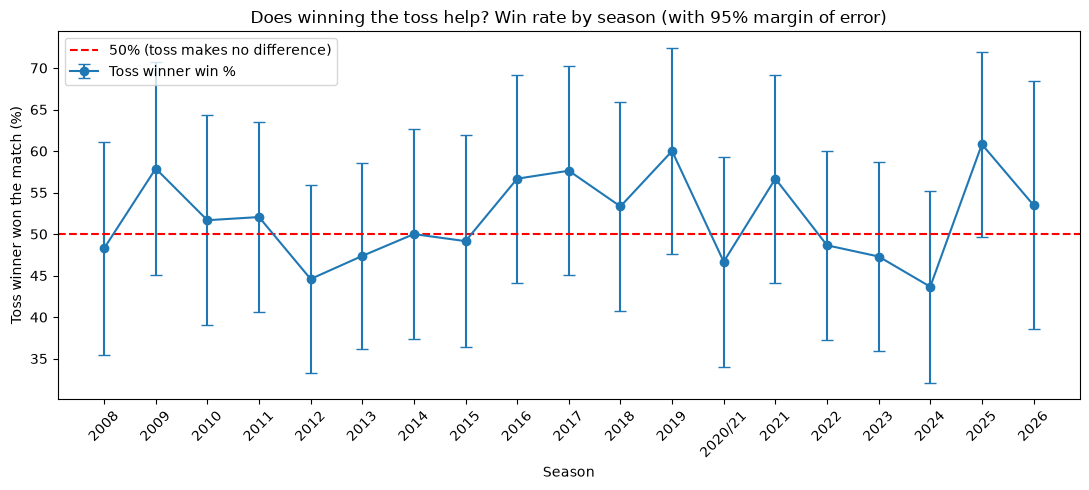

In [12]:
fig, ax = plt.subplots(figsize=(11, 5))

x = np.arange(len(by_season))
ax.errorbar(x, by_season['win_%'], yerr=by_season['margin_%'],
            fmt='o-', capsize=4, color='#1f77b4', label='Toss winner win %')
ax.axhline(50, color='red', linestyle='--', label='50% (toss makes no difference)')

ax.set_xticks(x)
ax.set_xticklabels(by_season.index, rotation=45)
ax.set_ylabel('Toss winner won the match (%)')
ax.set_xlabel('Season')
ax.set_title('Does winning the toss help? Win rate by season (with 95% margin of error)')
ax.legend()

plt.tight_layout()
plt.savefig('../images/q1_toss_by_season.png', dpi=150, bbox_inches='tight')
plt.show()

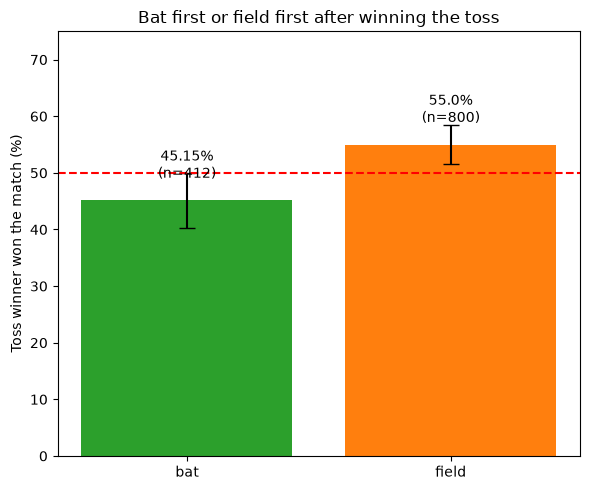

In [13]:
fig, ax = plt.subplots(figsize=(6, 5))

ax.bar(by_decision.index, by_decision['win_%'], yerr=by_decision['margin_%'],
       capsize=6, color=['#2ca02c', '#ff7f0e'])
ax.axhline(50, color='red', linestyle='--')

for i, (pct, n) in enumerate(zip(by_decision['win_%'], by_decision['matches'])):
    ax.text(i, pct + 4, f'{pct}%\n(n={n})', ha='center')

ax.set_ylim(0, 75)
ax.set_ylabel('Toss winner won the match (%)')
ax.set_title('Bat first or field first after winning the toss')

plt.tight_layout()
plt.savefig('../images/q1_toss_by_decision.png', dpi=150, bbox_inches='tight')
plt.show()

# Does the toss matter more at certain venues?

In [14]:
# Check the venue list
print(matches['venue'].nunique(), "venues")
print(matches['venue'].value_counts().to_string())

59 venues
venue
Eden Gardens                                                               77
Wankhede Stadium                                                           73
M Chinnaswamy Stadium                                                      65
Feroz Shah Kotla                                                           60
Wankhede Stadium, Mumbai                                                   57
Rajiv Gandhi International Stadium, Uppal                                  49
MA Chidambaram Stadium, Chepauk                                            48
Sawai Mansingh Stadium                                                     47
Dubai International Cricket Stadium                                        46
MA Chidambaram Stadium, Chepauk, Chennai                                   38
Narendra Modi Stadium, Ahmedabad                                           37
Punjab Cricket Association Stadium, Mohali                                 35
Sheikh Zayed Stadium                            

In [15]:
# Merge duplicate names

# Drop any ", City" suffix first (harmless if already done)
matches['venue'] = matches['venue'].str.split(',').str[0].str.strip()

VENUE_FIX = {
    'M.Chinnaswamy Stadium': 'M Chinnaswamy Stadium',
    'Feroz Shah Kotla': 'Arun Jaitley Stadium',
    'Punjab Cricket Association Stadium': 'Punjab Cricket Association IS Bindra Stadium',
    'Sardar Patel Stadium': 'Narendra Modi Stadium',
}
matches['venue'] = matches['venue'].replace(VENUE_FIX)

print(matches['venue'].nunique(), "venues after merging")

38 venues after merging


In [16]:
# Toss effect per venue, with a cutoff
played = matches[matches['has_result']].copy()

MIN_MATCHES = 20

by_venue = win_rate_table(played, 'venue')
by_venue = by_venue[by_venue['matches'] >= MIN_MATCHES].sort_values('win_%', ascending=False)

print(f"{len(by_venue)} venues with at least {MIN_MATCHES} matches")
by_venue

16 venues with at least 20 matches


,toss_winner_won,matches,win_%,margin_%,ci_low_%,ci_high_%
venue,,,,,,
Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium,18,26,69.23,17.74,51.49,86.97
Sharjah Cricket Stadium,16,28,57.14,18.33,38.81,75.47
Sawai Mansingh Stadium,37,66,56.06,11.97,44.09,68.03
Sheikh Zayed Stadium,16,29,55.17,18.10,37.07,73.27
M Chinnaswamy Stadium,57,104,54.81,9.57,45.24,64.38
Maharashtra Cricket Association Stadium,19,35,54.29,16.50,37.79,70.79
Dr DY Patil Sports Academy,20,37,54.05,16.06,37.99,70.11
Brabourne Stadium,14,27,51.85,18.85,33.00,70.70
Wankhede Stadium,67,130,51.54,8.59,42.95,60.13


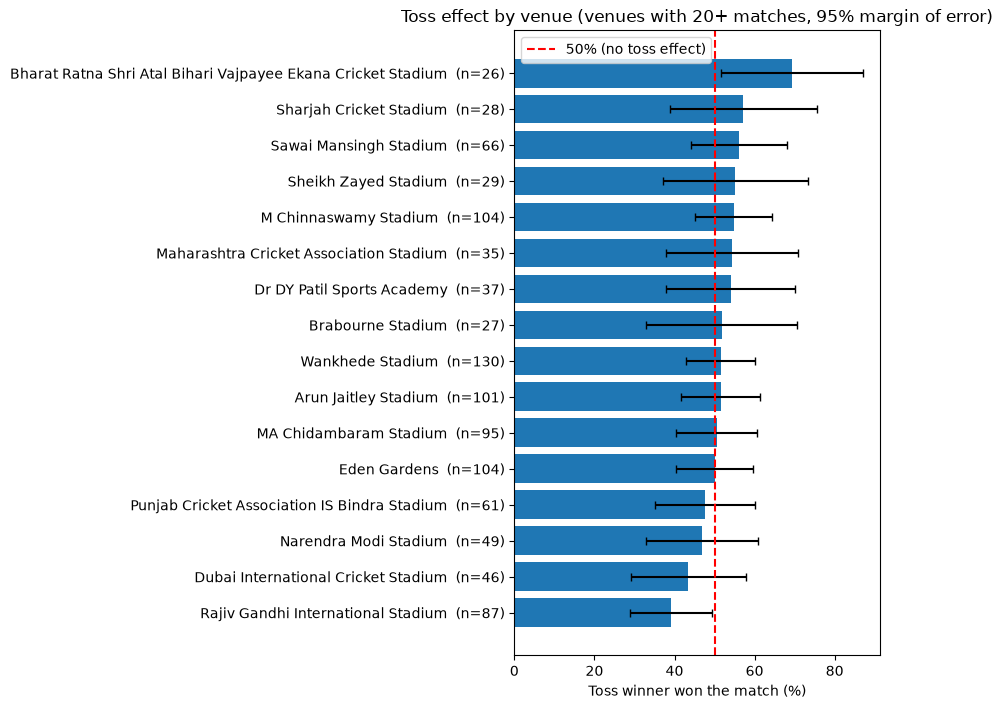

In [17]:
fig, ax = plt.subplots(figsize=(9, max(4, len(by_venue) * 0.45)))

d = by_venue.sort_values('win_%')
y = np.arange(len(d))
ax.barh(y, d['win_%'], xerr=d['margin_%'], capsize=3, color='#1f77b4')
ax.axvline(50, color='red', linestyle='--', label='50% (no toss effect)')

ax.set_yticks(y)
ax.set_yticklabels([f"{v}  (n={n})" for v, n in zip(d.index, d['matches'])])
ax.set_xlabel('Toss winner won the match (%)')
ax.set_title(f'Toss effect by venue (venues with {MIN_MATCHES}+ matches, 95% margin of error)')
ax.legend()

plt.tight_layout()
plt.savefig('../images/q1_toss_by_venue.png', dpi=150, bbox_inches='tight')
plt.show()

In [18]:
# How many venues look “significant”?
sig = by_venue[(by_venue['ci_low_%'] > 50) | (by_venue['ci_high_%'] < 50)]
print(f"{len(sig)} of {len(by_venue)} venues have an interval that excludes 50%")
sig[['matches', 'win_%', 'ci_low_%', 'ci_high_%']]

2 of 16 venues have an interval that excludes 50%


,matches,win_%,ci_low_%,ci_high_%
venue,,,,
Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium,26,69.23,51.49,86.97
Rajiv Gandhi International Stadium,87,39.08,28.83,49.33


# Wrap up Q1, then start Q2 ?

In [19]:
played = matches[matches['has_result']].copy()

n = len(played)
p = played['toss_win_match_win'].mean()
margin = 1.96 * np.sqrt(p * (1 - p) / n)
lo, hi = p - margin, p + margin

print(f"Toss winners won {p:.1%} of {n} decided matches (95% CI {lo:.1%} to {hi:.1%}).")
if lo <= 0.5 <= hi:
    print("Verdict: the interval includes 50%, so there is no clear toss advantage.")
else:
    print("Verdict: the interval excludes 50%, so the toss gives a real (if small) edge.")

by_decision = win_rate_table(played, 'toss_decision')
print()
print(by_decision[['matches', 'win_%', 'ci_low_%', 'ci_high_%']])

Toss winners won 51.7% of 1212 decided matches (95% CI 48.8% to 54.5%).
Verdict: the interval includes 50%, so there is no clear toss advantage.

               matches  win_%  ci_low_%  ci_high_%
toss_decision                                     
bat                412  45.15     40.34      49.96
field              800  55.00     51.55      58.45


# How has scoring changed across seasons ?

In [20]:
# --- Innings totals, per match (regular innings only, super overs excluded) ---
regular = balls[balls['is_super_over'] == 0]

totals = (regular.groupby(['match_id', 'innings'])['total_runs'].sum()
          .unstack().reindex(columns=[1, 2]))
totals.columns = ['first_inns_runs', 'second_inns_runs']

chasers = (regular[regular['innings'] == 2].groupby('match_id')['team_batting']
           .first().rename('chasing_team'))

matches = (matches.drop(columns=['first_inns_runs', 'second_inns_runs', 'chasing_team'], errors='ignore')
           .join(totals, on='match_id').join(chasers, on='match_id'))

# --- Ball-level flags used in Step 5 (created only if missing) ---
if 'is_legal_ball' not in balls.columns:
    balls['is_legal_ball'] = ((balls['is_wide_ball'] == 0) & (balls['is_no_ball'] == 0)).astype(int)
if 'is_four' not in balls.columns:
    balls['is_four'] = (balls['batter_runs'] == 4).astype(int)
if 'is_six' not in balls.columns:
    balls['is_six'] = (balls['batter_runs'] == 6).astype(int)

# --- Chase result flag ---
if 'has_result' not in matches.columns:
    matches['has_result'] = matches['match_winner'].isin(set(matches['team1']) | set(matches['team2']))
matches['chase_win'] = (matches['chasing_team'] == matches['match_winner']) & matches['has_result']

In [21]:
# Season for every ball
season_map = matches.set_index('match_id')['season']
reg = balls[balls['is_super_over'] == 0].copy()
reg['season'] = reg['match_id'].map(season_map)

# Match-level scoring
m = matches[matches['first_inns_runs'].notna()]
scoring = m.groupby('season').agg(
    matches=('match_id', 'count'),
    avg_first_inns=('first_inns_runs', 'mean'),
    median_first_inns=('first_inns_runs', 'median'),
    avg_second_inns=('second_inns_runs', 'mean'),
)

# Ball-level scoring
ball_stats = reg.groupby('season').agg(
    runs=('total_runs', 'sum'),
    legal_balls=('is_legal_ball', 'sum'),
    sixes=('is_six', 'sum'),
    fours=('is_four', 'sum'),
)
scoring['run_rate'] = (ball_stats['runs'] / ball_stats['legal_balls'] * 6).round(2)
scoring['sixes_per_match'] = (ball_stats['sixes'] / scoring['matches']).round(1)
scoring['fours_per_match'] = (ball_stats['fours'] / scoring['matches']).round(1)

scoring = scoring.round(1)
scoring

,matches,avg_first_inns,median_first_inns,avg_second_inns,run_rate,sixes_per_match,fours_per_match
season,,,,,,,
2008,58,161.0,160.0,148.3,8.3,10.7,29.4
2009,57,150.3,149.0,136.1,7.5,8.9,23.1
2010,60,164.8,169.0,149.6,8.1,9.8,28.5
2011,73,152.4,156.0,139.3,7.7,8.8,26.2
2012,74,157.5,159.0,145.9,7.8,9.9,25.8
2013,76,155.9,158.0,140.7,7.7,8.9,27.0
2014,60,163.1,160.0,152.1,8.2,11.9,26.0
2015,59,166.3,167.0,146.9,8.4,11.7,27.2
2016,60,162.6,162.0,151.8,8.3,10.6,27.2


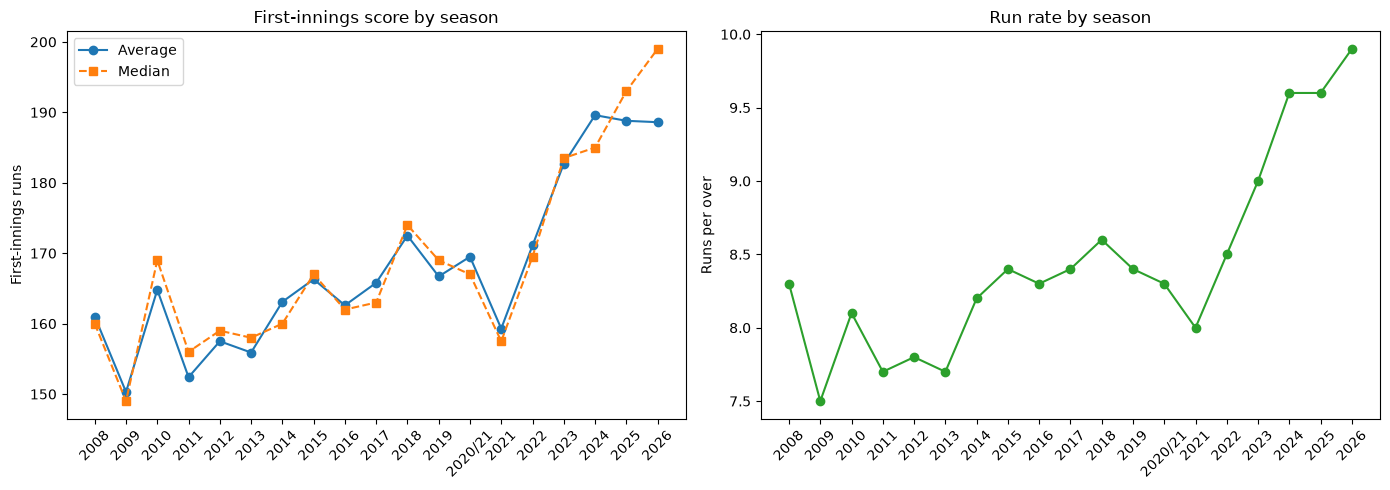

In [22]:
# Chart: first-innings score and run rate
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(scoring))
axes[0].plot(x, scoring['avg_first_inns'], 'o-', label='Average', color='#1f77b4')
axes[0].plot(x, scoring['median_first_inns'], 's--', label='Median', color='#ff7f0e')
axes[0].set_xticks(x)
axes[0].set_xticklabels(scoring.index, rotation=45)
axes[0].set_ylabel('First-innings runs')
axes[0].set_title('First-innings score by season')
axes[0].legend()

axes[1].plot(x, scoring['run_rate'], 'o-', color='#2ca02c')
axes[1].set_xticks(x)
axes[1].set_xticklabels(scoring.index, rotation=45)
axes[1].set_ylabel('Runs per over')
axes[1].set_title('Run rate by season')

plt.tight_layout()
plt.savefig('../images/q2_scoring_by_season.png', dpi=150, bbox_inches='tight')
plt.show()

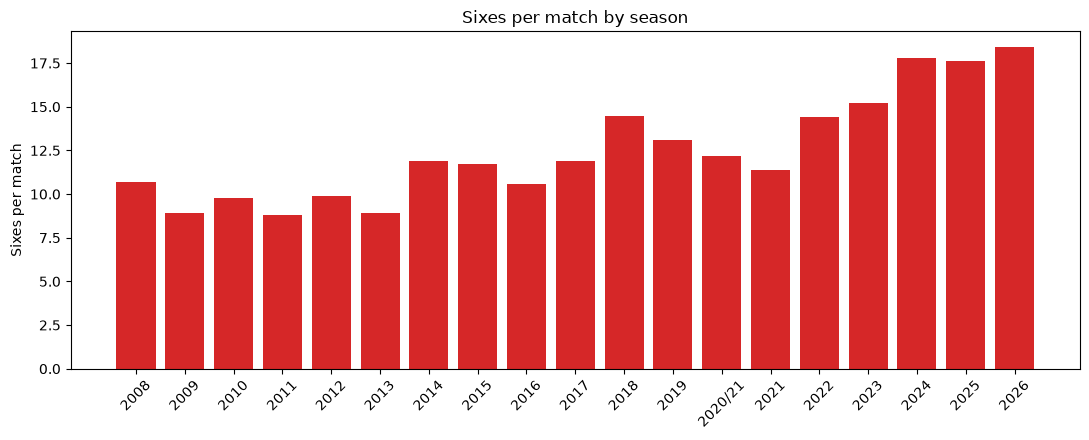

In [23]:
# Chart: sixes per match
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(scoring.index.astype(str), scoring['sixes_per_match'], color='#d62728')
ax.set_ylabel('Sixes per match')
ax.set_title('Sixes per match by season')
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('../images/q2_sixes_by_season.png', dpi=150, bbox_inches='tight')
plt.show()

# where are matches decided: powerplay, middle or death?

In [24]:
reg = balls[balls['is_super_over'] == 0].copy()

# 0-19 over number (over_number may have been dropped in the cleaning step)
if 'over0' not in reg.columns:
    offset = 0 if reg['over_number'].min() == 0 else 1
    reg['over0'] = reg['over_number'] - offset

reg['phase'] = pd.cut(reg['over0'], bins=[-1, 5, 14, 100],
                      labels=['Powerplay', 'Middle', 'Death']).astype(str)

if 'is_legal_ball' not in reg.columns:
    reg['is_legal_ball'] = ((reg['is_wide_ball'] == 0) & (reg['is_no_ball'] == 0)).astype(int)
if 'is_four' not in reg.columns:
    reg['is_four'] = (reg['batter_runs'] == 4).astype(int)
if 'is_six' not in reg.columns:
    reg['is_six'] = (reg['batter_runs'] == 6).astype(int)
reg['is_dot'] = ((reg['total_runs'] == 0) & (reg['is_legal_ball'] == 1)).astype(int)

print(reg['phase'].value_counts())
print("over0 range:", reg['over0'].min(), "to", reg['over0'].max())

phase
Middle       132173
Powerplay     90390
Death         65488
Name: count, dtype: int64
over0 range: 0 to 19


In [25]:
# What each phase looks like
order = ['Powerplay', 'Middle', 'Death']

ps = reg.groupby('phase').agg(
    runs=('total_runs', 'sum'),
    legal_balls=('is_legal_ball', 'sum'),
    wickets=('is_wicket', 'sum'),
    dots=('is_dot', 'sum'),
    boundaries=('is_four', 'sum'),
    sixes=('is_six', 'sum'),
).loc[order]

overs = ps['legal_balls'] / 6
phase_summary = pd.DataFrame({
    'runs_per_over': (ps['runs'] / overs).round(2),
    'wickets_per_over': (ps['wickets'] / overs).round(3),
    'dot_ball_%': (ps['dots'] / ps['legal_balls'] * 100).round(1),
    'boundary_%': ((ps['boundaries'] + ps['sixes']) / ps['legal_balls'] * 100).round(1),
})
phase_summary

,runs_per_over,wickets_per_over,dot_ball_%,boundary_%
phase,,,,
Powerplay,8.03,0.240,46.4,20.2
Middle,7.92,0.260,31.8,14.1
Death,10.04,0.508,28.4,20.7


In [26]:
# Winners vs losers in each phase (first innings only)
inn1 = reg[reg['innings'] == 1]

team_phase = (inn1.groupby(['match_id', 'team_batting', 'phase'])
              .agg(runs=('total_runs', 'sum'), legal=('is_legal_ball', 'sum'), wkts=('is_wicket', 'sum'))
              .reset_index())
team_phase['rpo'] = team_phase['runs'] / (team_phase['legal'] / 6)

# Attach match result
res = matches.loc[matches['has_result'], ['match_id', 'match_winner']]
team_phase = team_phase.merge(res, on='match_id')
team_phase['won'] = team_phase['team_batting'] == team_phase['match_winner']

cmp_ = (team_phase.groupby(['phase', 'won'])['rpo'].mean().unstack().loc[order])
cmp_.columns = ['lost_rpo', 'won_rpo']
cmp_['gap'] = (cmp_['won_rpo'] - cmp_['lost_rpo']).round(2)
cmp_['correlation_with_winning'] = [
    team_phase.loc[team_phase['phase'] == ph, ['rpo', 'won']].astype(float).corr().iloc[0, 1].round(3)
    for ph in order]
cmp_.round(2)

,lost_rpo,won_rpo,gap,correlation_with_winning
phase,,,,
Powerplay,7.42,8.45,1.03,0.24
Middle,7.34,8.61,1.26,0.32
Death,9.42,11.21,1.80,0.30


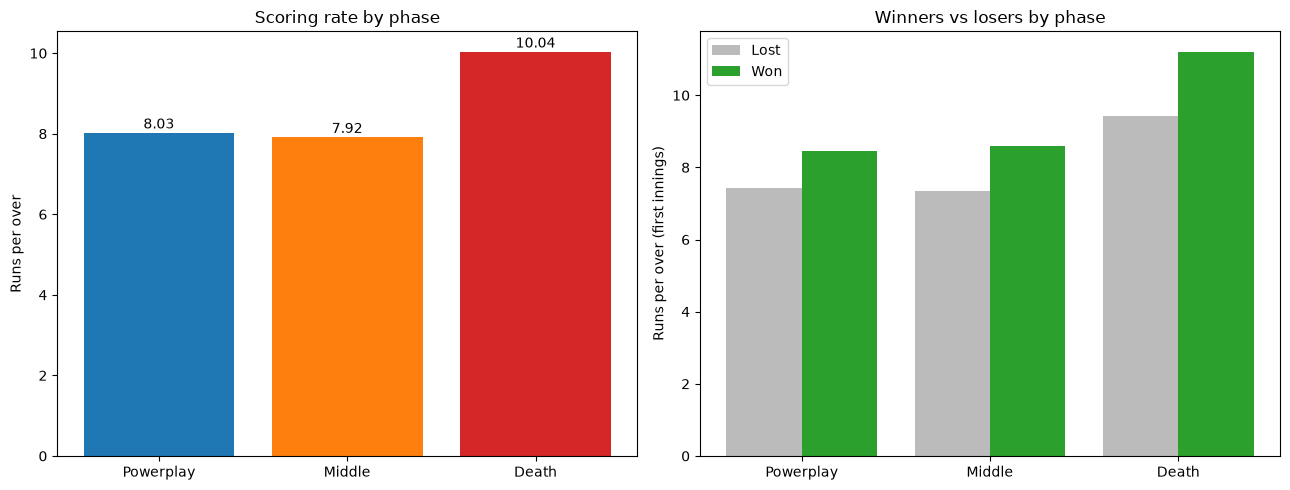

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: tempo of each phase
axes[0].bar(order, phase_summary['runs_per_over'], color=['#1f77b4', '#ff7f0e', '#d62728'])
for i, v in enumerate(phase_summary['runs_per_over']):
    axes[0].text(i, v + 0.1, f'{v}', ha='center')
axes[0].set_ylabel('Runs per over')
axes[0].set_title('Scoring rate by phase')

# Right: winners vs losers
x = np.arange(3)
axes[1].bar(x - 0.2, cmp_['lost_rpo'], 0.4, label='Lost', color='#bbbbbb')
axes[1].bar(x + 0.2, cmp_['won_rpo'], 0.4, label='Won', color='#2ca02c')
axes[1].set_xticks(x)
axes[1].set_xticklabels(order)
axes[1].set_ylabel('Runs per over (first innings)')
axes[1].set_title('Winners vs losers by phase')
axes[1].legend()

plt.tight_layout()
plt.savefig('../images/q3_phases.png', dpi=150, bbox_inches='tight')
plt.show()

# which venues favour batters and which favour bowlers?

In [28]:
reg = balls[balls['is_super_over'] == 0].copy()

if 'is_legal_ball' not in reg.columns:
    reg['is_legal_ball'] = ((reg['is_wide_ball'] == 0) & (reg['is_no_ball'] == 0)).astype(int)
if 'is_six' not in reg.columns:
    reg['is_six'] = (reg['batter_runs'] == 6).astype(int)

# Venue and season come from matches, so they always agree with the cleaned venue names
reg = reg.merge(matches[['match_id', 'venue', 'season']], on='match_id', how='left')
print("Balls with no venue:", reg['venue'].isna().sum())

Balls with no venue: 0


In [29]:
# Match-level table
mm = reg.groupby('match_id').agg(
    runs=('total_runs', 'sum'),
    legal=('is_legal_ball', 'sum'),
    wickets=('is_wicket', 'sum'),
    sixes=('is_six', 'sum'),
    venue=('venue', 'first'),
    season=('season', 'first'),
)

mm = mm[mm['legal'] >= 200]          # drops rain-shortened matches (a full match has about 240 legal balls)
mm['run_rate'] = mm['runs'] / mm['legal'] * 6
mm['rr_vs_season'] = mm['run_rate'] - mm.groupby('season')['run_rate'].transform('mean')

print(len(mm), "full-length matches kept")

1132 full-length matches kept


In [30]:
# Venue table
MIN_MATCHES = 20

venue_tbl = mm.groupby('venue').agg(
    matches=('run_rate', 'count'),
    run_rate=('run_rate', 'mean'),
    vs_season_avg=('rr_vs_season', 'mean'),
    spread=('rr_vs_season', 'std'),
    wickets_per_match=('wickets', 'mean'),
    sixes_per_match=('sixes', 'mean'),
)
venue_tbl['margin'] = 1.96 * venue_tbl['spread'] / np.sqrt(venue_tbl['matches'])

venue_tbl = venue_tbl[venue_tbl['matches'] >= MIN_MATCHES].drop(columns='spread')
venue_tbl = venue_tbl.sort_values('vs_season_avg', ascending=False).round(2)

# Does the interval exclude zero? Only then is the venue clearly different from the season norm
venue_tbl['clear_difference'] = (venue_tbl['vs_season_avg'].abs() > venue_tbl['margin'])
venue_tbl

,matches,run_rate,vs_season_avg,wickets_per_match,sixes_per_match,margin,clear_difference
venue,,,,,,,
Brabourne Stadium,25,9.06,0.63,12.36,13.12,0.35,True
M Chinnaswamy Stadium,92,8.88,0.36,11.99,16.09,0.23,True
Punjab Cricket Association IS Bindra Stadium,57,8.54,0.29,11.18,10.19,0.27,True
Wankhede Stadium,125,8.70,0.19,12.03,14.38,0.23,False
Arun Jaitley Stadium,95,8.66,0.17,11.89,13.47,0.25,False
Eden Gardens,91,8.65,0.13,11.79,13.86,0.23,False
Narendra Modi Stadium,47,8.98,-0.02,12.23,15.74,0.30,False
Sawai Mansingh Stadium,63,8.45,-0.03,10.71,10.46,0.23,False
Rajiv Gandhi International Stadium,81,8.40,-0.15,11.95,12.28,0.29,False


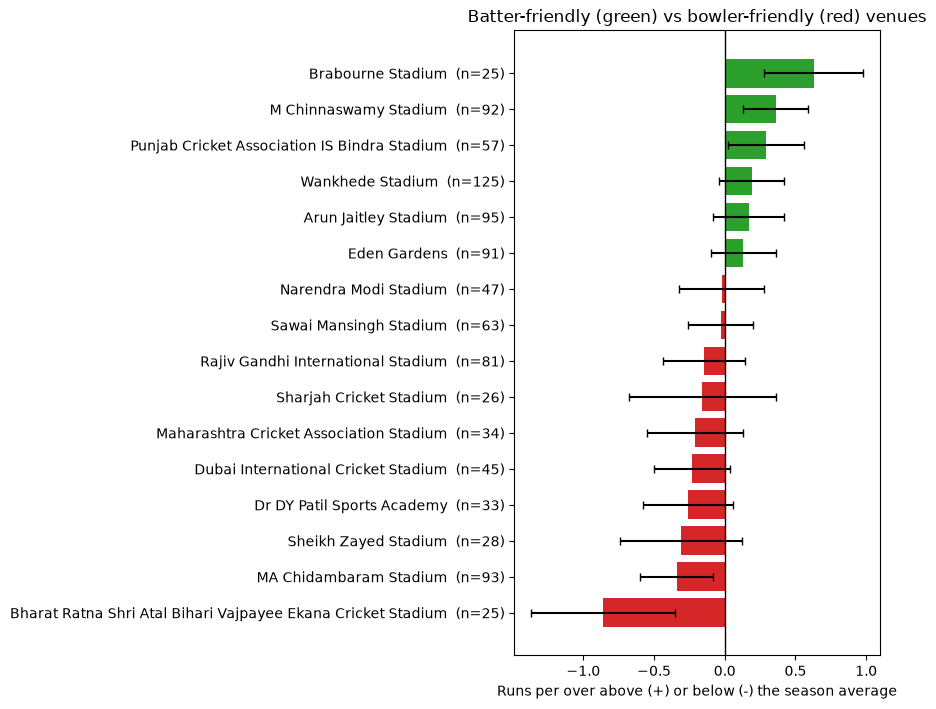

In [31]:
d = venue_tbl.sort_values('vs_season_avg')
colors = ['#2ca02c' if v > 0 else '#d62728' for v in d['vs_season_avg']]

fig, ax = plt.subplots(figsize=(9, max(4, len(d) * 0.45)))
ax.barh(np.arange(len(d)), d['vs_season_avg'], xerr=d['margin'], capsize=3, color=colors)
ax.axvline(0, color='black', linewidth=1)

ax.set_yticks(np.arange(len(d)))
ax.set_yticklabels([f"{v}  (n={n})" for v, n in zip(d.index, d['matches'])])
ax.set_xlabel('Runs per over above (+) or below (-) the season average')
ax.set_title('Batter-friendly (green) vs bowler-friendly (red) venues')

plt.tight_layout()
plt.savefig('../images/q4_venues.png', dpi=150, bbox_inches='tight')
plt.show()

# is chasing more successful now than in 2008

In [32]:
# Chasing team = the team batting in innings 2 (regular innings only)
regular = balls[balls['is_super_over'] == 0]

if 'chasing_team' not in matches.columns:
    chasers = (regular[regular['innings'] == 2].groupby('match_id')['team_batting']
               .first().rename('chasing_team'))
    matches = matches.join(chasers, on='match_id')

if 'has_result' not in matches.columns:
    matches['has_result'] = matches['match_winner'].isin(set(matches['team1']) | set(matches['team2']))

matches['chase_win'] = (matches['chasing_team'] == matches['match_winner']) & matches['has_result']

played = matches[matches['has_result'] & matches['chasing_team'].notna()].copy()
print(len(played), "decided matches with a chasing team")
print("Overall chase win %:", round(played['chase_win'].mean() * 100, 1))

1206 decided matches with a chasing team
Overall chase win %: 54.7


In [33]:
# Chase success by season
def rate_table(df, by, col):
    g = df.groupby(by)[col].agg(['sum', 'count'])
    g.columns = ['wins', 'matches']
    g['win_%'] = (g['wins'] / g['matches'] * 100).round(1)
    p = g['wins'] / g['matches']
    g['margin_%'] = (1.96 * np.sqrt(p * (1 - p) / g['matches']) * 100).round(1)
    return g

chase_by_season = rate_table(played, 'season', 'chase_win')
chase_by_season

,wins,matches,win_%,margin_%
season,,,,
2008,36,58,62.1,12.5
2009,30,57,52.6,13.0
2010,28,60,46.7,12.6
2011,40,72,55.6,11.5
2012,40,74,54.1,11.4
2013,37,76,48.7,11.2
2014,37,60,61.7,12.3
2015,25,58,43.1,12.7
2016,41,60,68.3,11.8


In [34]:
# Is there a trend
y = chase_by_season['win_%'].values
x = np.arange(len(y))

slope, intercept = np.polyfit(x, y, 1)
print(f"Trend: {slope:+.2f} percentage points per season")
print(f"Fitted change over {len(y)} seasons: {slope * (len(y) - 1):+.1f} points")

Trend: +0.07 percentage points per season
Fitted change over 19 seasons: +1.3 points


In [35]:
seasons = list(chase_by_season.index)
half = len(seasons) // 2
early, late = seasons[:half], seasons[half:]

for label, group in [('Early', early), ('Late', late)]:
    sub = played[played['season'].isin(group)]
    p = sub['chase_win'].mean()
    m = 1.96 * np.sqrt(p * (1 - p) / len(sub))
    print(f"{label} ({group[0]} to {group[-1]}): {p:.1%} chase wins, n={len(sub)}, 95% CI {p-m:.1%} to {p+m:.1%}")

Early (2008 to 2016): 54.6% chase wins, n=575, 95% CI 50.5% to 58.7%
Late (2017 to 2026): 54.8% chase wins, n=631, 95% CI 51.0% to 58.7%


In [36]:
# What the toss decisions look like (context for the trend)
matches['chose_field'] = (matches['toss_decision'].str.lower() == 'field')
field_share = (matches.groupby('season')['chose_field'].mean() * 100).round(1)
field_share

season
2008       55.2
2009       38.6
2010       35.0
2011       65.8
2012       50.0
2013       40.8
2014       68.3
2015       57.6
2016       81.7
2017       81.4
2018       83.3
2019       83.3
2020/21    55.0
2021       73.3
2022       79.7
2023       71.6
2024       73.2
2025       81.1
2026       83.7
Name: chose_field, dtype: float64

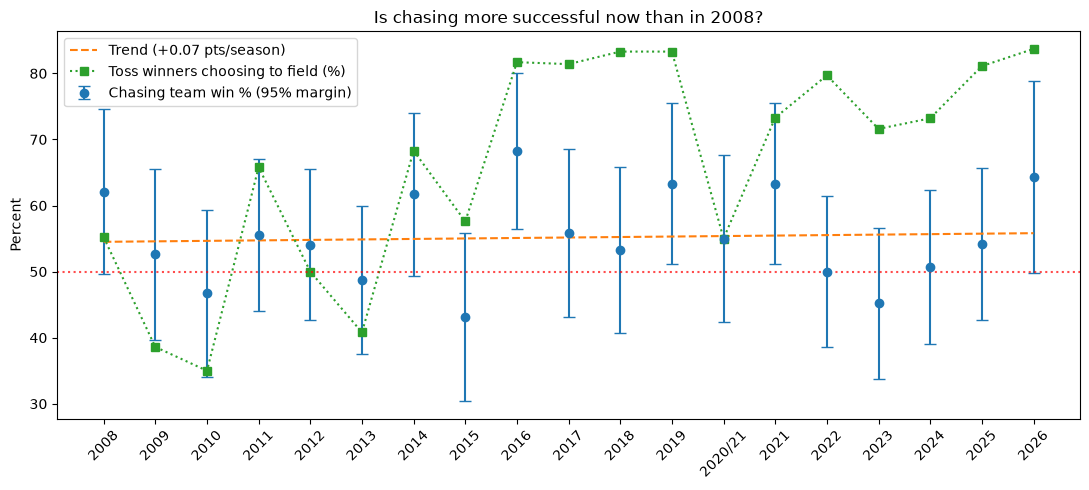

In [37]:
fig, ax = plt.subplots(figsize=(11, 5))

x = np.arange(len(chase_by_season))
ax.errorbar(x, chase_by_season['win_%'], yerr=chase_by_season['margin_%'],
            fmt='o', capsize=4, color='#1f77b4', label='Chasing team win % (95% margin)')
ax.plot(x, intercept + slope * x, '--', color='#ff7f0e', label=f'Trend ({slope:+.2f} pts/season)')
ax.plot(x, field_share.reindex(chase_by_season.index).values, 's:', color='#2ca02c',
        label='Toss winners choosing to field (%)')
ax.axhline(50, color='red', linestyle=':', alpha=0.7)

ax.set_xticks(x)
ax.set_xticklabels(chase_by_season.index, rotation=45)
ax.set_ylabel('Percent')
ax.set_title('Is chasing more successful now than in 2008?')
ax.legend()

plt.tight_layout()
plt.savefig('../images/q5_chasing_by_season.png', dpi=150, bbox_inches='tight')
plt.show()

# who are the most impactful batters and bowlers?

In [38]:
reg = balls[balls['is_super_over'] == 0].copy()

# Rebuild any helper columns that may have been dropped earlier
reg['is_legal_ball'] = ((reg['is_wide_ball'] == 0) & (reg['is_no_ball'] == 0)).astype(int)
reg['ball_faced'] = (reg['is_wide_ball'] == 0).astype(int)   # batters face no-balls, not wides
reg['is_four'] = (reg['batter_runs'] == 4).astype(int)
reg['is_six'] = (reg['batter_runs'] == 6).astype(int)
reg['is_dot'] = ((reg['total_runs'] == 0) & (reg['is_legal_ball'] == 1)).astype(int)

# Runs charged to the bowler: everything except byes and leg byes
bye_ball = ((reg['is_bye'] == 1) | (reg['is_leg_bye'] == 1)).astype(int)
reg['bowler_runs'] = reg['total_runs'] - reg['extras'] * bye_ball

print(reg['wicket_kind'].value_counts())
print(reg['player_out'].value_counts().head(3))

wicket_kind
NA                       273742
caught                     9045
bowled                     2398
run out                    1167
lbw                         871
caught and bowled           399
stumped                     382
retired hurt                 19
hit wicket                   18
retired out                   6
obstructing the field         4
Name: count, dtype: int64
player_out
NA           273742
RG Sharma       241
V Kohli         226
Name: count, dtype: int64


In [39]:
BOWLER_WICKETS = ['bowled', 'caught', 'lbw', 'stumped', 'caught and bowled', 'hit wicket']   # run-outs don't count for the bowler
NOT_OUT = ['none', 'NA', 'Unknown', '']

reg['is_bowler_wicket'] = reg['wicket_kind'].str.lower().isin(BOWLER_WICKETS).astype(int)

MIN_BALLS_BAT = 500      # about 83 overs faced
MIN_BALLS_BOWL = 500     # about 83 overs bowled

In [40]:
bat = reg.groupby('batter').agg(
    matches=('match_id', 'nunique'),
    runs=('batter_runs', 'sum'),
    balls_faced=('ball_faced', 'sum'),
    fours=('is_four', 'sum'),
    sixes=('is_six', 'sum'),
)

dismissals = (reg[~reg['player_out'].isin(NOT_OUT)]
              .groupby('player_out').size().rename('dismissals'))
bat = bat.join(dismissals).fillna({'dismissals': 0})

bat['strike_rate'] = (bat['runs'] / bat['balls_faced'] * 100).round(1)
bat['average'] = (bat['runs'] / bat['dismissals'].replace(0, np.nan)).round(1)
bat['boundary_%'] = ((bat['fours'] + bat['sixes']) / bat['balls_faced'] * 100).round(1)

bat = bat[bat['balls_faced'] >= MIN_BALLS_BAT]
print(len(bat), f"batters with {MIN_BALLS_BAT}+ balls faced")

top_runs = bat.sort_values('runs', ascending=False).head(15)
top_runs

137 batters with 500+ balls faced


,matches,runs,balls_faced,fours,sixes,dismissals,strike_rate,average,boundary_%
batter,,,,,,,,,
V Kohli,268,9040,6748,814,307,226.0,134.0,40.0,16.6
RG Sharma,270,7183,5417,653,311,241.0,132.6,29.8,17.8
S Dhawan,221,6769,5324,768,153,193.0,127.1,35.1,17.3
DA Warner,184,6565,4697,663,236,162.0,139.8,40.5,19.1
KL Rahul,144,5655,4072,494,232,121.0,138.9,46.7,17.8
SK Raina,200,5528,4043,506,203,170.0,136.7,32.5,17.5
MS Dhoni,241,5439,3957,375,264,142.0,137.5,38.3,16.1
AM Rahane,191,5194,4145,523,133,172.0,125.3,30.2,15.8
AB de Villiers,170,5162,3403,413,251,130.0,151.7,39.7,19.5


In [41]:
# best by strike rate
bat.sort_values('strike_rate', ascending=False).head(15)[['matches', 'runs', 'balls_faced', 'average', 'boundary_%', 'strike_rate']]

,matches,runs,balls_faced,average,boundary_%,strike_rate
batter,,,,,,
TH David,52,1038,588,35.8,24.1,176.5
PD Salt,40,1258,721,34.0,28.4,174.5
AD Russell,114,2651,1522,28.2,26.9,174.2
Abhishek Sharma,83,2241,1317,29.9,26.3,170.2
TM Head,46,1408,834,33.5,26.7,168.8
H Klaasen,54,1894,1135,43.0,20.9,166.9
SP Narine,122,1820,1101,17.5,28.2,165.3
N Pooran,94,2375,1458,31.7,22.9,162.9
RM Patidar,46,1368,848,31.8,21.5,161.3


In [42]:
bowl = reg.groupby('bowler').agg(
    matches=('match_id', 'nunique'),
    runs_conceded=('bowler_runs', 'sum'),
    legal_balls=('is_legal_ball', 'sum'),
    wickets=('is_bowler_wicket', 'sum'),
    dots=('is_dot', 'sum'),
)

bowl['economy'] = (bowl['runs_conceded'] / (bowl['legal_balls'] / 6)).round(2)
bowl['average'] = (bowl['runs_conceded'] / bowl['wickets'].replace(0, np.nan)).round(1)
bowl['strike_rate'] = (bowl['legal_balls'] / bowl['wickets'].replace(0, np.nan)).round(1)   # balls per wicket
bowl['dot_%'] = (bowl['dots'] / bowl['legal_balls'] * 100).round(1)

bowl = bowl[bowl['legal_balls'] >= MIN_BALLS_BOWL]
print(len(bowl), f"bowlers with {MIN_BALLS_BOWL}+ legal balls")

top_wkts = bowl.sort_values('wickets', ascending=False).head(15)
top_wkts

149 bowlers with 500+ legal balls


,matches,runs_conceded,legal_balls,wickets,dots,economy,average,strike_rate,dot_%
bowler,,,,,,,,,
YS Chahal,179,5273,3941,228,1298,8.03,23.1,17.3,32.9
B Kumar,199,5676,4432,215,1828,7.68,26.4,20.6,41.2
SP Narine,194,5102,4507,199,1719,6.79,25.6,22.6,38.1
PP Chawla,191,5108,3850,192,1325,7.96,26.6,20.1,34.4
R Ashwin,217,5652,4710,187,1606,7.20,30.2,25.2,34.1
JJ Bumrah,153,4295,3517,185,1409,7.33,23.2,19.0,40.1
DJ Bravo,158,4360,3120,183,998,8.38,23.8,17.0,32.0
RA Jadeja,233,5358,4188,177,1330,7.68,30.3,23.7,31.8
A Mishra,162,4145,3371,174,1185,7.38,23.8,19.4,35.2


In [43]:
# most economical
bowl.sort_values('economy').head(15)[['matches', 'wickets', 'economy', 'average', 'strike_rate', 'dot_%']]

,matches,wickets,economy,average,strike_rate,dot_%
bowler,,,,,,
A Kumble,42,45,6.58,23.5,21.4,38.8
M Muralitharan,66,63,6.68,26.9,24.2,39.2
SP Narine,194,199,6.79,25.6,22.6,38.1
DL Vettori,34,28,6.79,31.4,27.8,34.7
DW Steyn,95,97,6.92,25.9,22.4,46.8
J Botha,34,25,6.92,32.0,27.8,36.6
R Sharma,44,40,7.02,27.2,23.2,36.0
Harbhajan Singh,160,150,7.08,26.9,22.8,37.0
SL Malinga,122,170,7.15,19.8,16.6,40.5


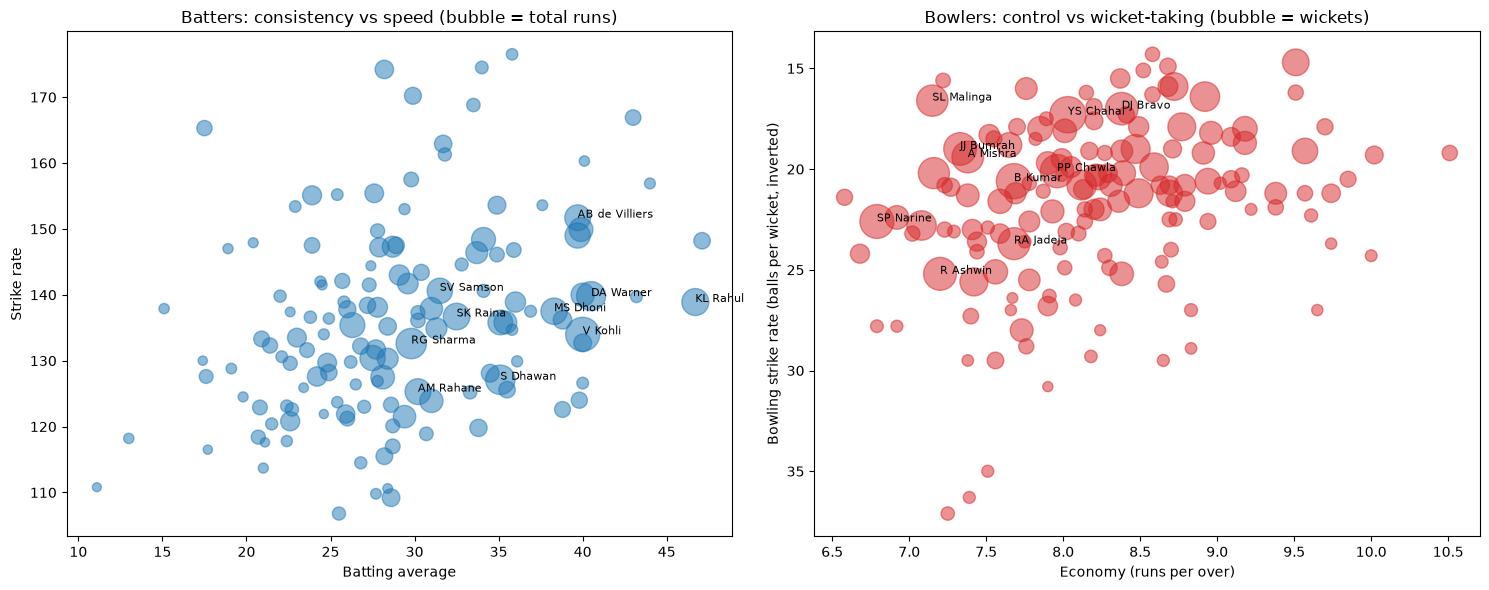

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Batters: strike rate vs average, bubble = runs
ax = axes[0]
b = bat.dropna(subset=['average'])
ax.scatter(b['average'], b['strike_rate'], s=b['runs'] / 15, alpha=0.5, color='#1f77b4')
for name, r in b.sort_values('runs', ascending=False).head(10).iterrows():
    ax.annotate(name, (r['average'], r['strike_rate']), fontsize=8)
ax.set_xlabel('Batting average')
ax.set_ylabel('Strike rate')
ax.set_title('Batters: consistency vs speed (bubble = total runs)')

# Bowlers: economy vs strike rate, bubble = wickets
ax = axes[1]
w = bowl.dropna(subset=['strike_rate'])
ax.scatter(w['economy'], w['strike_rate'], s=w['wickets'] * 3, alpha=0.5, color='#d62728')
for name, r in w.sort_values('wickets', ascending=False).head(10).iterrows():
    ax.annotate(name, (r['economy'], r['strike_rate']), fontsize=8)
ax.invert_yaxis()   # fewer balls per wicket = better, so up is better
ax.set_xlabel('Economy (runs per over)')
ax.set_ylabel('Bowling strike rate (balls per wicket, inverted)')
ax.set_title('Bowlers: control vs wicket-taking (bubble = wickets)')

plt.tight_layout()
plt.savefig('../images/q6_players.png', dpi=150, bbox_inches='tight')
plt.show()

In [45]:
offset = 0 if balls['over_number'].min() == 0 else 1
balls['over0'] = balls['over_number'] - offset
reg['over0'] = reg['over_number'] - offset

print("over0 range:", reg['over0'].min(), "to", reg['over0'].max())

over0 range: 0 to 19


In [46]:
# death-over specialists
death = reg[reg['over0'] >= 15]

d_bat = death.groupby('batter').agg(runs=('batter_runs', 'sum'), balls=('ball_faced', 'sum'))
d_bat = d_bat[d_bat['balls'] >= 200]
d_bat['strike_rate'] = (d_bat['runs'] / d_bat['balls'] * 100).round(1)
print("Best death-over batters (200+ balls):")
print(d_bat.sort_values('strike_rate', ascending=False).head(10))

d_bowl = death.groupby('bowler').agg(runs=('bowler_runs', 'sum'), balls=('is_legal_ball', 'sum'),
                                     wickets=('is_bowler_wicket', 'sum'))
d_bowl = d_bowl[d_bowl['balls'] >= 200]
d_bowl['economy'] = (d_bowl['runs'] / (d_bowl['balls'] / 6)).round(2)
print("\nBest death-over bowlers (200+ balls):")
print(d_bowl.sort_values('economy').head(10))

Best death-over batters (200+ balls):
                runs  balls  strike_rate
batter                                  
AB de Villiers  1868    838        222.9
T Stubbs         533    258        206.6
CH Gayle         581    284        204.6
RR Pant         1035    516        200.6
Shashank Singh   489    248        197.2
TH David         788    401        196.5
AD Russell      1432    731        195.9
Tilak Varma      485    250        194.0
H Klaasen        702    362        193.9
JC Buttler       750    389        192.8

Best death-over bowlers (200+ balls):
                 runs  balls  wickets  economy
bowler                                        
SP Narine        1307   1075       79     7.29
DE Bollinger      292    234       23     7.49
SL Malinga       1464   1117      108     7.86
M Muralitharan    373    275       22     8.14
JJ Bumrah        1911   1393      102     8.23
R Ashwin          825    601       36     8.24
DW Steyn          877    634       50     8.30
Harbhaja

# The story of IPL Data Analysis 

In [47]:
def show(title, obj_name, cols=None, n=None):
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)
    if obj_name not in globals():
        print(f"MISSING: '{obj_name}' not found. Re-run the step that creates it.")
        return
    obj = globals()[obj_name]
    if cols:
        obj = obj[[c for c in cols if c in obj.columns]]
    print(obj.head(n).to_string() if n else obj.to_string())

# Q1: toss
if 'matches' in globals() and 'has_result' in matches.columns:
    pl = matches[matches['has_result']]
    p = pl['toss_win_match_win'].mean(); n_ = len(pl); mg = 1.96 * np.sqrt(p * (1 - p) / n_)
    print(f"Q1 OVERALL: toss winners won {p:.1%} of {n_} matches (95% CI {p-mg:.1%} to {p+mg:.1%})")
show("Q1 by decision", 'by_decision', ['matches', 'win_%', 'ci_low_%', 'ci_high_%'])
show("Q1 by season", 'by_season', ['matches', 'win_%', 'margin_%'])
show("Q1 by venue", 'by_venue', ['matches', 'win_%', 'ci_low_%', 'ci_high_%'])

# Q2: scoring
show("Q2 scoring by season", 'scoring')

# Q3: phases
show("Q3 phase summary", 'phase_summary')
show("Q3 winners vs losers (1st innings)", 'cmp_')

# Q4: venues
show("Q4 venues", 'venue_tbl', ['matches', 'run_rate', 'vs_season_avg', 'margin', 'clear_difference'])

# Q5: chasing
show("Q5 chase success by season", 'chase_by_season')
if 'slope' in globals():
    print(f"\nQ5 trend: {slope:+.2f} percentage points per season")

# Q6: players
show("Q6 top run scorers", 'top_runs', ['runs', 'balls_faced', 'strike_rate', 'average'], 10)
show("Q6 top wicket takers", 'top_wkts', ['wickets', 'economy', 'average', 'strike_rate'], 10)

Q1 OVERALL: toss winners won 51.7% of 1212 matches (95% CI 48.8% to 54.5%)

Q1 by decision
               matches  win_%  ci_low_%  ci_high_%
toss_decision                                     
bat                412  45.15     40.34      49.96
field              800  55.00     51.55      58.45

Q1 by season
         matches  win_%  margin_%
season                           
2008          58  48.28     12.86
2009          57  57.89     12.82
2010          60  51.67     12.64
2011          73  52.05     11.46
2012          74  44.59     11.33
2013          76  47.37     11.23
2014          60  50.00     12.65
2015          59  49.15     12.76
2016          60  56.67     12.54
2017          59  57.63     12.61
2018          60  53.33     12.62
2019          60  60.00     12.40
2020/21       60  46.67     12.62
2021          60  56.67     12.54
2022          74  48.65     11.39
2023          74  47.30     11.38
2024          71  43.66     11.54
2025          74  60.81     11.12
2026       